# Phase 2: Data Understanding (MIMIC-IV Clinical Database Demo 2.2)

**Goal of this notebook:** find out what the data can and cannot support *before* we build features or models.

Questions answered here:
1. How many patients, ICU stays and measurements do we have?
2. How many positive cases do the two labels have? (readmission within 30 days; deterioration within 24 hours)
3. Which vital signs and labs are available, and how often are they measured?
4. Can we compute NEWS2 and MEWS as baselines?

Every number below is computed by the code in the cell above it. The label logic itself lives in `ml/data/mimic_demo.py`, so Phase 3 reuses exactly the same definitions.

## 0. Setup
This cell makes the project importable, applies one consistent chart style, and loads the small tables.
`find_root()` locates the extracted dataset inside `data/raw/`, wherever the zip was unpacked.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ml.config import FIGURES_DIR
from ml.data.mimic_demo import (VITAL_ITEMS, find_root, load_core,
                                readmission_index, deterioration_windows)

# One restrained chart style: light surface, thin marks, quiet grid, dark-grey text.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

root = find_root()
core = load_core(root)
adm, pat, icu, proc = core["adm"], core["pat"], core["icu"], core["proc"]
print("dataset folder:", root.name)

dataset folder: mimic-iv-clinical-database-demo-2.2


## 1. Size of the dataset
We count rows in the tables we will use. `chartevents` holds the bedside vital signs, `labevents` the lab results.
Because the files are compressed CSVs, we read only one column of the big tables to count rows quickly.

In [2]:
def n_rows(path):
    return sum(len(c) for c in pd.read_csv(root / path, usecols=[0], chunksize=500_000))

sizes = pd.Series({
    "patients": len(pat),
    "hospital admissions": len(adm),
    "ICU stays": len(icu),
    "chartevents rows (ICU vitals/charting)": n_rows("icu/chartevents.csv.gz"),
    "labevents rows (labs)": n_rows("hosp/labevents.csv.gz"),
    "procedureevents rows (ventilation etc.)": len(proc),
}, name="count")
sizes.to_frame()

,count
patients,100
hospital admissions,275
ICU stays,140
chartevents rows (ICU vitals/charting),668862
labevents rows (labs),107727
procedureevents rows (ventilation etc.),1468


**Important structural fact.** In MIMIC-IV, `chartevents` is recorded **only while the patient is in the ICU**.
The check below confirms that every admission with vital signs also has an ICU stay.
That means there are **no ward vital signs** in this dataset, which affects how we can define deterioration (section 4).

In [3]:
hadm_with_vitals = set()
for chunk in pd.read_csv(root / "icu/chartevents.csv.gz", usecols=["hadm_id"], chunksize=500_000):
    hadm_with_vitals |= set(chunk.hadm_id.unique())
print("admissions with vitals:", len(hadm_with_vitals))
print("admissions with an ICU stay:", icu.hadm_id.nunique())
print("vitals only exist for ICU admissions:", hadm_with_vitals <= set(icu.hadm_id))

admissions with vitals: 128
admissions with an ICU stay: 128
vitals only exist for ICU admissions: True


## 2. Cohort funnel
Starting from all patients, we apply the rules from `docs/scope.md`: adults only, and patients who died in the ICU cannot be readmitted, so they are excluded from the **readmission** task.

In [4]:
ri = readmission_index(adm, icu)          # excludes stays that ended in death
adults = pat[pat.anchor_age >= 18].subject_id
funnel = pd.DataFrame({
    "step": ["Patients in demo", "Adult patients", "Patients with an ICU stay", "ICU stays (all)",
             "ICU stays that ended in death (excluded)", "Index stays for readmission task"],
    "count": [len(pat), len(adults), icu[icu.subject_id.isin(adults)].subject_id.nunique(), len(icu),
              len(icu) - len(ri), len(ri)],
})
funnel

,step,count
0,Patients in demo,100
1,Adult patients,100
2,Patients with an ICU stay,100
3,ICU stays (all),140
4,ICU stays that ended in death (excluded),12
5,Index stays for readmission task,128


## 3. Task 2 label: ICU readmission
`readmission_index()` finds, for each ICU discharge, the same patient's **next** ICU admission and the gap in hours.
We then count how many stays are followed by a readmission within 48 hours, 7 days and 30 days.

Why this matters: too few positive cases make a window unusable, because a model cannot learn (or be tested) from a handful of events.

,window,positive stays,of index stays,rate,distinct patients with an event
0,48 hours,8,128,6.2%,6
1,7 days,14,128,10.9%,10
2,30 days,21,128,16.4%,15


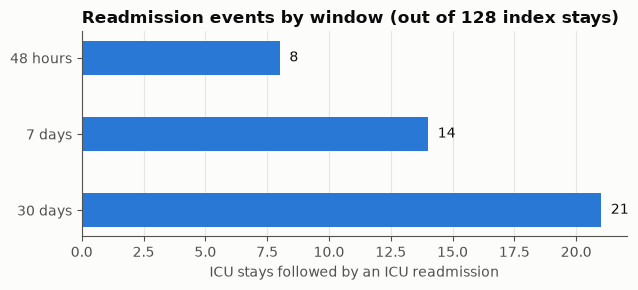

In [5]:
windows = {"48 hours": "readmit_48h", "7 days": "readmit_7d", "30 days": "readmit_30d"}
rows = []
for name, col in windows.items():
    pos = ri[ri[col] == 1]
    rows.append({"window": name, "positive stays": len(pos), "of index stays": len(ri),
                 "rate": f"{len(pos) / len(ri):.1%}", "distinct patients with an event": pos.subject_id.nunique()})
readmit_table = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.5, 3))
bars = ax.barh(readmit_table["window"], readmit_table["positive stays"], color=BLUE, height=0.45)
ax.invert_yaxis()
for b, v in zip(bars, readmit_table["positive stays"]):
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2, str(v), va="center", color=INK)
ax.set_xlabel("ICU stays followed by an ICU readmission")
ax.set_title(f"Readmission events by window (out of {len(ri)} index stays)")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "readmission_events.png", dpi=150)
readmit_table

**Reading this:** the 30-day window has the most events, but they come from only a handful of patients.
The 48-hour window has too few events to evaluate reliably. This supports keeping **30 days** as the primary window.

## 4. Task 1 label: clinical deterioration
**Problem with the literature definition.** The MIMIC-IV deterioration paper used ICU transfer + ventilation + death.
But our data has vital signs *only inside the ICU*, so "ICU transfer" cannot be predicted from ward vitals; those vitals do not exist here.

**Adapted definition (within the ICU):** every 6 hours during an ICU stay we create a prediction time point.
The label is 1 if the patient **starts invasive ventilation or dies within the next 24 hours**.
`on_vent` marks time points where the patient is already ventilated. We keep those points (ventilation status is a useful feature), and for them only death can be a new event.

In [6]:
w = deterioration_windows(adm, icu, proc, step_h=6, horizon_h=24)
pos = w[w.y == 1]
summary = pd.Series({
    "prediction time points": len(w),
    "ICU stays covered": w.stay_id.nunique(),
    "patients covered": w.subject_id.nunique(),
    "time points already on a ventilator": int(w.on_vent.sum()),
    "positive time points": len(pos),
    "prevalence": f"{w.y.mean():.2%}",
    "patients with at least one positive": pos.subject_id.nunique(),
    "  of which new ventilation": pos[pos.vent_next].subject_id.nunique(),
    "  of which death": pos[pos.death_next].subject_id.nunique(),
}, name="value")
summary.to_frame()

,value
prediction time points,1986
ICU stays covered,137
patients covered,99
time points already on a ventilator,787
positive time points,88
prevalence,4.43%
patients with at least one positive,20
of which new ventilation,11
of which death,11


share of positives from the 5 patients with most events: 39%


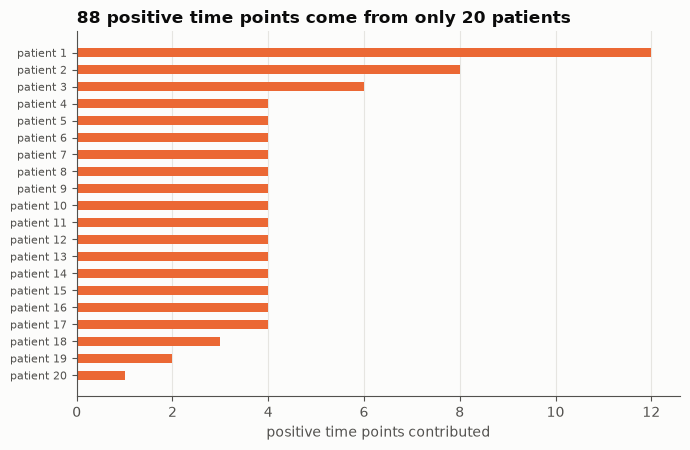

In [7]:
per_patient = pos.groupby("subject_id").size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(range(len(per_patient)), per_patient.values, color=ORANGE, height=0.55)
ax.set_yticks(range(len(per_patient)))
ax.set_yticklabels([f"patient {i + 1}" for i in range(len(per_patient))], fontsize=8)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("positive time points contributed")
ax.set_title(f"{len(pos)} positive time points come from only {len(per_patient)} patients")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "deterioration_positives_per_patient.png", dpi=150)
print("share of positives from the 5 patients with most events:", f"{per_patient.head(5).sum() / len(pos):.0%}")

**Reading this:** neighbouring time points from the same patient are strongly correlated, so the *effective* sample size is closer to the number of **patients** with events than to the number of positive rows.
This is why every split must be **by patient**, and why results will have wide uncertainty.

## 5. Which vital signs exist, and how often are they measured?
We load only the vital-sign items we care about (listed in `VITAL_ITEMS`) from the large `chartevents` table.
For each item: in how many of the 140 ICU stays does it appear, and what is the median number of observations per hour of ICU stay?

,item,stays with data,median obs per hour
0,Heart Rate,140,1.04
1,Respiratory Rate,140,1.04
2,SpO2,140,1.03
3,NBP systolic,139,0.89
4,ABP systolic,65,0.77
5,Temperature C,15,0.29
6,Temperature F,138,0.26
7,O2 delivery device,138,0.25
8,GCS motor,140,0.23
9,GCS eye,140,0.23


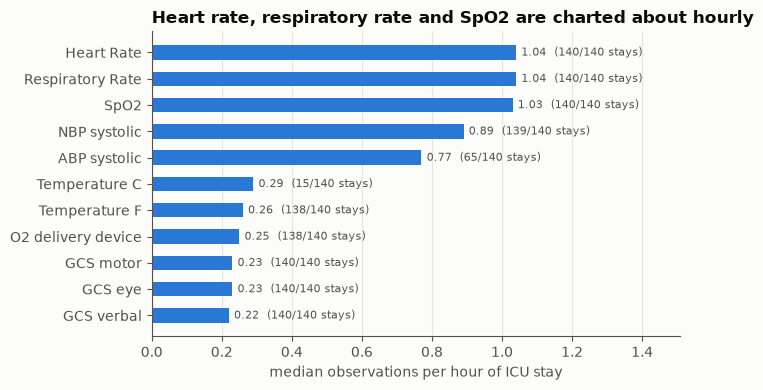

In [8]:
ce = pd.read_csv(root / "icu/chartevents.csv.gz", usecols=["stay_id", "charttime", "itemid", "valuenum"],
                 parse_dates=["charttime"])
ce = ce[ce.itemid.isin(VITAL_ITEMS)]
los_h = (icu.outtime - icu.intime).dt.total_seconds().div(3600)
los_h.index = icu.stay_id

rows = []
for item_id, name in VITAL_ITEMS.items():
    d = ce[ce.itemid == item_id]
    per_stay = d.groupby("stay_id").size().reindex(icu.stay_id).fillna(0)
    rate = per_stay.values / los_h.reindex(icu.stay_id).values
    rows.append({"item": name, "stays with data": int((per_stay > 0).sum()),
                 "median obs per hour": round(float(np.median(rate[per_stay.values > 0])), 2) if (per_stay > 0).any() else 0.0})
vitals = pd.DataFrame(rows).sort_values("median obs per hour", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(vitals["item"], vitals["median obs per hour"], color=BLUE, height=0.55)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
for y, (v, n) in enumerate(zip(vitals["median obs per hour"], vitals["stays with data"])):
    ax.text(v + 0.015, y, f"{v:.2f}  ({n}/{len(icu)} stays)", va="center", fontsize=8, color=MUTED)
ax.set_xlim(0, vitals["median obs per hour"].max() * 1.45)
ax.set_xlabel("median observations per hour of ICU stay")
ax.set_title("Heart rate, respiratory rate and SpO2 are charted about hourly")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "vitals_frequency.png", dpi=150)
vitals.reset_index(drop=True)

**Reading this:** HR, RR, SpO2 and blood pressure are charted roughly every hour, which is enough to compute trends.
Temperature and GCS (consciousness) are charted about every 4 hours. Arterial blood pressure exists only for some stays, so we use non-invasive pressure as the main source and arterial as a fallback.

## 6. Can we compute NEWS2 and MEWS?
NEWS2 and MEWS need heart rate, respiratory rate, SpO2 (NEWS2), systolic BP, temperature and a consciousness measure (we use GCS verbal as a proxy for the AVPU scale).
For each 6-hour time point from section 4, we check whether each input was measured in the **previous 6 hours**.

all six inputs present: 85.9%
all except GCS present: 94.1%


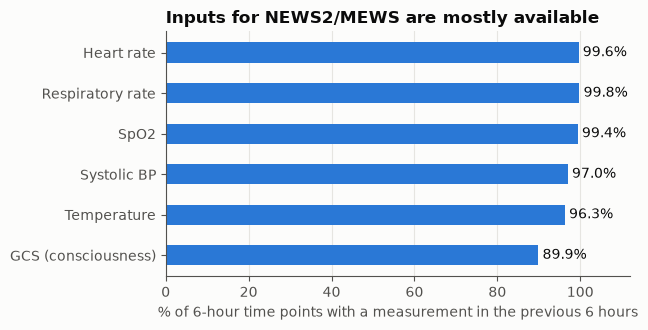

In [9]:
def measured_in_prior_window(item_ids, wdf, hours=6):
    times = {k: v.charttime.values for k, v in ce[ce.itemid.isin(item_ids)].groupby("stay_id")}
    out = np.zeros(len(wdf), dtype=bool)
    delta = np.timedelta64(hours, "h")
    for i, (sid, t) in enumerate(zip(wdf.stay_id.values, wdf.t.values)):
        a = times.get(sid)
        if a is not None:
            out[i] = ((a > t - delta) & (a <= t)).any()
    return out

inputs = {"Heart rate": [220045], "Respiratory rate": [220210], "SpO2": [220277],
          "Systolic BP": [220179, 220050], "Temperature": [223761, 223762], "GCS (consciousness)": [223900]}
avail = pd.DataFrame({k: measured_in_prior_window(v, w) for k, v in inputs.items()})
share = (avail.mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh(share.index, share.values, color=BLUE, height=0.5)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlim(0, 112)
for y, v in enumerate(share.values):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", color=INK)
ax.set_xlabel("% of 6-hour time points with a measurement in the previous 6 hours")
ax.set_title("Inputs for NEWS2/MEWS are mostly available")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "score_input_availability.png", dpi=150)
print(f"all six inputs present: {avail.all(axis=1).mean():.1%}")
print(f"all except GCS present: {avail.drop(columns='GCS (consciousness)').all(axis=1).mean():.1%}")

**Reading this:** NEWS2/MEWS can be computed for the large majority of time points, so we can use them as baselines.
Where an input is missing, we carry forward the last known value (with a limit) and record how often we had to do so.

## 7. Which labs exist?
Labs are recorded per hospital admission (not only in the ICU). We list the most frequently measured labs for the admissions that have an ICU stay.

In [10]:
lab = pd.read_csv(root / "hosp/labevents.csv.gz", usecols=["hadm_id", "itemid", "valuenum"])
d_lab = pd.read_csv(root / "hosp/d_labitems.csv.gz")
lab = lab[lab.hadm_id.isin(icu.hadm_id)]
top_labs = (lab.groupby("itemid").agg(rows=("itemid", "size"), admissions=("hadm_id", "nunique"))
               .sort_values("rows", ascending=False).head(15).reset_index()
               .merge(d_lab[["itemid", "label"]], on="itemid")[["label", "rows", "admissions"]])
top_labs

,label,rows,admissions
0,Sodium,1670,128
1,Potassium,1669,128
2,Chloride,1666,128
3,Creatinine,1587,128
4,Bicarbonate,1585,128
5,Urea Nitrogen,1583,128
6,Anion Gap,1582,128
7,Hematocrit,1578,128
8,Glucose,1557,128
9,Magnesium,1526,128


## 8. Findings and what they mean for the next phases

| Finding | Consequence |
|---|---|
| 100 patients, 140 ICU stays, about 670k charted rows | Enough to build and test the pipeline; too small for strong conclusions. Report wide uncertainty. |
| 30-day readmission: ~21 events, ~15 patients; 48-hour: ~8 events | Keep **30 days** as the primary window. Do not use 48 hours. |
| Vitals exist only in the ICU | Deterioration is defined **within the ICU**; ICU transfer is dropped from the composite. |
| Deterioration positives: ~88 time points from only 20 patients | Splits must be by patient; use repeated stratified patient-level cross-validation. |
| HR, RR, SpO2, BP about hourly; temperature, GCS about every 4 h | Enough for trend features over 6 to 24 hours. |
| NEWS2/MEWS inputs available for most time points | Compute both scores as baselines on our own cohort. |
| LSTM needs many samples | Expect it may not beat tree models on this data; report that honestly. |

The cell outputs above are the evidence for each row. If you rerun this notebook on the full MIMIC-IV later, the same code runs unchanged and these numbers update.